# Installs and Imports

In [ ]:
!pip install -q accelerate

In [ ]:
!pip install -U bitsandbytes>=0.46.1

In [ ]:
import json, os, time, re, glob, copy, inspect, subprocess, sys
from packaging.version import Version

from google.colab import drive

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit, log_expit
from scipy.stats import kendalltau, pearsonr

from datasets import load_dataset

from sklearn.linear_model import LogisticRegression

import torch, transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

In [ ]:
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

In [ ]:
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#333333",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})

# Config

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
assert torch.cuda.is_available()

In [ ]:
NOTEBOOK_DIR = "path"
PROMPT_MODE = "reason" # or "verdict"

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"

MAX_CHARS = 6000
MAX_INPUT_TOKENS = 7000
MAX_REASON_TOKENS = 80
N_JUDGE = 1500

CAL_FRAC = 0.25
TEST_SHARE_OF_R = 2 / 3
N_REPS = 200
LAMBDA_GRID = [0.1, 0.25, 0.5, 0.75]
MARGIN_QUANTILES = [0.0, 0.1, 0.2, 0.3, 0.4]
RHO = 0.2
M_SMOOTH = 5
P_FLOOR = 1e-6
SEED = 0

A, B, E = 0, 1, 2

In [ ]:
os.makedirs(NOTEBOOK_DIR, exist_ok=True)
RUN_NAME = f"judge_hf_{PROMPT_MODE}"
CACHE_FILE = os.path.join(NOTEBOOK_DIR, RUN_NAME + ".jsonl")
J_FILE = os.path.join(NOTEBOOK_DIR, "judge_J_ids.json")

# Model

In [ ]:
DEV = torch.device("cuda:0")
tok = AutoTokenizer.from_pretrained(MODEL_ID)
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                          bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
kw = dict(quantization_config=bnb, device_map={"": 0}, attn_implementation="sdpa")
kw["dtype" if Version(transformers.__version__) >= Version("4.56") else "torch_dtype"] = torch.float16
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **kw).eval()
params = inspect.signature(model.forward).parameters
LOGITS_KW = {"logits_to_keep": 1} if "logits_to_keep" in params else (
            {"num_logits_to_keep": 1} if "num_logits_to_keep" in params else {})

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

# Data

In [ ]:
PREF_MAP = {"A-is-clearly-better": A, "A-is-slightly-better": A, "Tie": E,
            "B-is-slightly-better": B, "B-is-clearly-better": B}

In [ ]:
raw = load_dataset("allenai/multipref", split="train").to_pandas()
raw.head()

README.md:   0%|          | 0.00/16.2k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10461 [00:00<?, ? examples/s]

,comparison_id,prompt_id,text,model_a,completion_a,model_b,completion_b,source,category,subject_study,highest_level_degree,normal_worker_annotations,expert_worker_annotations
0,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,but it will provide acceleration in y directio...,gpt-4-turbo-2024-04-09,To calculate the distance traveled in the y-di...,meta-llama/Meta-Llama-3-70B-Instruct,To find the distance traveled in the y-directi...,lmsys/sharegpt-vicuna,Open QA,Physics,Mathematics and statistics,"[{'evaluator': 'mystifying_fermi', 'harmless_c...","[{'evaluator': 'affectionate_shirley', 'harmle..."
1,aa8af1e5ea024ad08e71273f5695993b,000616d1471540e4935f6c60ecc06aeb,what are some fun sandwiches i can make for kids?,allenai/tulu-2-7b,Here are a few fun sandwich ideas that kids mi...,meta-llama/Meta-Llama-3-70B-Instruct,"Kids love sandwiches, and making them fun can ...",anthropic/helpful-base,Brainstorm,Leisure,Arts & Humanities,"[{'evaluator': 'romantic_liskov', 'harmless_ch...","[{'evaluator': 'cocky_davinci', 'harmless_chec..."
2,6b9671fb535b447e898a24771d136306,000616d1471540e4935f6c60ecc06aeb,what are some fun sandwiches i can make for kids?,allenai/tulu-2-70b,Here are a few ideas for fun sandwiches that k...,gpt-4-turbo-2024-04-09,Making sandwiches for kids is not only about p...,anthropic/helpful-base,Brainstorm,Leisure,Arts & Humanities,"[{'evaluator': 'practical_agnesi', 'harmless_c...","[{'evaluator': 'cocky_davinci', 'harmless_chec..."
3,924dbf961d664b1c8634a0d831f0c8d4,00117e5830704b6a8d448a6400e3cf8e,what are august activiites for copenhagen rank...,allenai/tulu-2-70b,"I'm sorry, but I don't have information about ...",meta-llama/Llama-2-70b-chat-hf,Here are some popular activities to do in Co...,lmsys/sharegpt-vicuna,Open QA,Travel and Tourism,Journalism & Information Business,"[{'evaluator': 'suspicious_saha', 'harmless_ch...","[{'evaluator': 'elastic_roentgen', 'harmless_c..."
4,fb0315fba0f1484994e2a9b3e7e1d4cb,00117e5830704b6a8d448a6400e3cf8e,what are august activiites for copenhagen rank...,allenai/tulu-2-7b,Here are some popular activities to do in Cope...,allenai/tulu-2-70b,"I'm sorry, but I don't have information about ...",lmsys/sharegpt-vicuna,Open QA,Travel and Tourism,Journalism & Information Business,"[{'evaluator': 'unruffled_hoover', 'harmless_c...","[{'evaluator': 'festive_euclid', 'harmless_che..."


In [ ]:
raw.shape

(10461, 13)

In [ ]:
rows = []
for r in raw.itertuples(index=False):
    for group, col in [("normal", "normal_worker_annotations"), ("expert", "expert_worker_annotations")]:
        anns = getattr(r, col)
        for i, a_ in enumerate([] if anns is None else list(anns)):
            rows.append(dict(comparison_id=r.comparison_id, prompt_id=r.prompt_id, category=r.category,
                             model_a=r.model_a, model_b=r.model_b, slot=f"{group}_{i}",
                             y=PREF_MAP.get(a_.get("overall_pref"))))
ann = pd.DataFrame(rows).dropna(subset=["y"])
ann["y"] = ann.y.astype(int)
ann.head()

,comparison_id,prompt_id,category,model_a,model_b,slot,y
0,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,0
1,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_1,0
2,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_0,0
3,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_1,0
4,aa8af1e5ea024ad08e71273f5695993b,000616d1471540e4935f6c60ecc06aeb,Brainstorm,allenai/tulu-2-7b,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,1


In [ ]:
MODELS = sorted(set(raw.model_a) | set(raw.model_b))
K = len(MODELS)
SHORT = {m: m.split("/")[-1] for m in MODELS}
idx = {m: i for i, m in enumerate(MODELS)}
ann["a"], ann["b"] = ann.model_a.map(idx), ann.model_b.map(idx)
ann["self_pair"] = ann.a == ann.b
ann.head()

,comparison_id,prompt_id,category,model_a,model_b,slot,y,a,b,self_pair
0,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,0,3,5,False
1,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_1,0,3,5,False
2,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_0,0,3,5,False
3,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_1,0,3,5,False
4,aa8af1e5ea024ad08e71273f5695993b,000616d1471540e4935f6c60ecc06aeb,Brainstorm,allenai/tulu-2-7b,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,1,1,5,False


In [ ]:
comp = raw.set_index("comparison_id")
comp["a"], comp["b"] = comp.model_a.map(idx), comp.model_b.map(idx)
comp.head()

,prompt_id,text,model_a,completion_a,model_b,completion_b,source,category,subject_study,highest_level_degree,normal_worker_annotations,expert_worker_annotations,a,b
comparison_id,,,,,,,,,,,,,,
cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,but it will provide acceleration in y directio...,gpt-4-turbo-2024-04-09,To calculate the distance traveled in the y-di...,meta-llama/Meta-Llama-3-70B-Instruct,To find the distance traveled in the y-directi...,lmsys/sharegpt-vicuna,Open QA,Physics,Mathematics and statistics,"[{'evaluator': 'mystifying_fermi', 'harmless_c...","[{'evaluator': 'affectionate_shirley', 'harmle...",3,5
aa8af1e5ea024ad08e71273f5695993b,000616d1471540e4935f6c60ecc06aeb,what are some fun sandwiches i can make for kids?,allenai/tulu-2-7b,Here are a few fun sandwich ideas that kids mi...,meta-llama/Meta-Llama-3-70B-Instruct,"Kids love sandwiches, and making them fun can ...",anthropic/helpful-base,Brainstorm,Leisure,Arts & Humanities,"[{'evaluator': 'romantic_liskov', 'harmless_ch...","[{'evaluator': 'cocky_davinci', 'harmless_chec...",1,5
6b9671fb535b447e898a24771d136306,000616d1471540e4935f6c60ecc06aeb,what are some fun sandwiches i can make for kids?,allenai/tulu-2-70b,Here are a few ideas for fun sandwiches that k...,gpt-4-turbo-2024-04-09,Making sandwiches for kids is not only about p...,anthropic/helpful-base,Brainstorm,Leisure,Arts & Humanities,"[{'evaluator': 'practical_agnesi', 'harmless_c...","[{'evaluator': 'cocky_davinci', 'harmless_chec...",0,3
924dbf961d664b1c8634a0d831f0c8d4,00117e5830704b6a8d448a6400e3cf8e,what are august activiites for copenhagen rank...,allenai/tulu-2-70b,"I'm sorry, but I don't have information about ...",meta-llama/Llama-2-70b-chat-hf,Here are some popular activities to do in Co...,lmsys/sharegpt-vicuna,Open QA,Travel and Tourism,Journalism & Information Business,"[{'evaluator': 'suspicious_saha', 'harmless_ch...","[{'evaluator': 'elastic_roentgen', 'harmless_c...",0,4
fb0315fba0f1484994e2a9b3e7e1d4cb,00117e5830704b6a8d448a6400e3cf8e,what are august activiites for copenhagen rank...,allenai/tulu-2-7b,Here are some popular activities to do in Cope...,allenai/tulu-2-70b,"I'm sorry, but I don't have information about ...",lmsys/sharegpt-vicuna,Open QA,Travel and Tourism,Journalism & Information Business,"[{'evaluator': 'unruffled_hoover', 'harmless_c...","[{'evaluator': 'festive_euclid', 'harmless_che...",1,0


In [ ]:
WIDE = ann.pivot_table(index="comparison_id", columns="slot", values="y", aggfunc="first")
WIDE

slot,expert_0,expert_1,normal_0,normal_1
comparison_id,,,,
00049cf5d0c343799d58deb812737db4,1,1,1,1
0014136ad3c74943ada801d51b15c26f,1,0,0,1
00151a18ea43481382a3774867cd323d,2,1,1,1
001856e14208453186469738b03e229a,2,2,1,1
0018c94453ce402bb3baddac9d5238cf,2,1,2,2
...,...,...,...,...
fff3c07eb70b4d0a8388fe2310607b64,0,1,1,0
fff8b5db278b475f87c985f64ae72734,2,0,2,1
fffc875af3344f03b1575419db69dbe9,2,0,2,0


In [ ]:
HUMAN_TIE = ann.groupby("comparison_id").y.apply(lambda s: (s == E).mean())
HUMAN_TIE

,y
comparison_id,
00049cf5d0c343799d58deb812737db4,0.00
0014136ad3c74943ada801d51b15c26f,0.00
00151a18ea43481382a3774867cd323d,0.25
001856e14208453186469738b03e229a,0.50
0018c94453ce402bb3baddac9d5238cf,0.75
...,...
fff3c07eb70b4d0a8388fe2310607b64,0.00
fff8b5db278b475f87c985f64ae72734,0.50
fffc875af3344f03b1575419db69dbe9,0.50


In [ ]:
print(f"Pairs: {len(raw)}, Prompts: {raw.prompt_id.nunique()}, Models: {K}")

Pairs: 10461, Prompts: 5323, Models: 6


# Split: J (judge) and R (human reference)

In [85]:
rng0 = np.random.default_rng(SEED)
saved = json.load(open(J_FILE)) if os.path.exists(J_FILE) else None
if saved is not None and saved.get("N_JUDGE") == N_JUDGE:
    J_ids, J_cal_prompts = saved["J_ids"], set(saved["J_cal_prompts"])
else:
    cross = raw[raw.model_a != raw.model_b]
    per_prompt = cross.groupby("prompt_id").comparison_id.apply(list)
    order = rng0.permutation(per_prompt.index.to_numpy())
    J_prompts, J_ids = [], []
    for p in order:
        J_prompts.append(p)
        J_ids.extend(per_prompt[p])
        if len(J_ids) >= N_JUDGE:
            break
    step = round(1 / CAL_FRAC)
    J_cal_prompts = set(J_prompts[::step])
    json.dump({"N_JUDGE": N_JUDGE, "J_ids": J_ids, "J_cal_prompts": sorted(J_cal_prompts)}, open(J_FILE, "w"))

J_set = set(J_ids)
J_prompt_set = set(comp.loc[J_ids].prompt_id)
J_cal_ids = [c for c in J_ids if comp.loc[c, "prompt_id"] in J_cal_prompts]
J_rank_ids = [c for c in J_ids if comp.loc[c, "prompt_id"] not in J_cal_prompts]
R_prompts = np.array(sorted(set(raw.prompt_id) - J_prompt_set))
print(f"J: {len(J_ids)} pairs (calibration {len(J_cal_ids)}, ranking {len(J_rank_ids)}); "
      f"R: {len(R_prompts)} prompts for the reference")

J: 1501 pairs (calibration 380, ranking 1121); R: 4351 prompts for the reference


In [ ]:
PLAN_FILE = os.path.join(NOTEBOOK_DIR, "collect_qwen2.5-7b-instruct", "plan.json")
if os.path.exists(PLAN_FILE):
    same = set(json.load(open(PLAN_FILE, encoding="utf-8"))["J_prompts"]) == J_prompt_set
    print("J matches the collection notebook:", same)

J matches the collection notebook: True


# Prompts and Judge

In [ ]:
DEFS = "\n".join([
    "You are an impartial expert judge. You compare two AI assistant responses to the same user prompt",
    "and decide which one is better overall: more helpful, more correct and truthful, safer, and better at following",
    "the user's instructions. Do not let the order of the responses, their length, or their style alone influence you.",
    "",
    "Choose exactly one verdict:",
    '- "A": Response A is better overall.',
    '- "B": Response B is better overall.',
    '- "Equivalent": you can evaluate both responses with confidence, and they are of practically equal quality',
    "  (equally good or equally bad). Any differences would not matter to the user.",
    '- "Abstain": you cannot reliably judge which response is better. For example, you lack the knowledge to verify',
    "  correctness, the prompt is ambiguous, or the responses are too hard to compare.",
    "",
    '"Equivalent" means you are confident that they are equally good. "Abstain" means you are not able to tell.',
    ""])
SYSTEM_PROMPTS = {"reason": DEFS + 'Answer in JSON: first "reason" (one short sentence), then "verdict".',
                  "verdict": DEFS + 'Answer in JSON with a single field "verdict".'}
SYSTEM_PROMPT = SYSTEM_PROMPTS[PROMPT_MODE]
LABELS = ["A", "B", "Equivalent", "Abstain"]
CHAR_LIMITS = [MAX_CHARS, 4000, 2500, 1500]

In [ ]:
def clip(text, n=MAX_CHARS):
    text = "" if text is None else str(text)
    return (text, False) if len(text) <= n else (text[:n] + "\n[... response truncated ...]", True)

def build_user_message(prompt, resp_a, resp_b, max_chars=MAX_CHARS):
    p, tp = clip(prompt, 4000)
    ra, ta = clip(resp_a, max_chars)
    rb, tb = clip(resp_b, max_chars)
    msg = f"[User prompt]\n{p}\n\n[Response A]\n{ra}\n\n[Response B]\n{rb}"
    return msg, (tp or ta or tb)

def label_ids_after(prefix):
    base = tok(prefix, add_special_tokens=False)["input_ids"]
    out = []
    for lab in LABELS:
        full_ids = tok(prefix + lab + '"}', add_special_tokens=False)["input_ids"]
        rest = full_ids[len(base):] if full_ids[:len(base)] == base else []
        ks = [k for k in range(1, len(rest) + 1) if tok.decode(rest[:k]) == lab]
        out.append(rest[:ks[0]] if ks else tok(lab, add_special_tokens=False)["input_ids"])
    assert len({c[0] for c in out}) == 4, f"label first tokens collide: {out}"
    return out

In [ ]:
VERDICT_PREFIX = {"reason": '", "verdict": "', "verdict": '{"verdict": "'}[PROMPT_MODE]
LABEL_IDS = label_ids_after(VERDICT_PREFIX)
QUOTE_T = torch.tensor([i for i in range(len(tok)) if tok.decode([i]).startswith('"')], device=DEV)
print("Label tokens:", {lab: [tok.decode([t]) for t in c] for lab, c in zip(LABELS, LABEL_IDS)})
CACHE_MODE = {"crop": None}
QUOTE_RE = re.compile(r'(?<!\\)"')

Label tokens: {'A': ['A'], 'B': ['B'], 'Equivalent': ['Equivalent'], 'Abstain': ['Ab', 'st', 'ain']}


In [ ]:
def chat_text(msg):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": msg}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def _crop_ok(pk, n, T):
    try:
        pk.crop(-n)
        return (not hasattr(pk, "get_seq_length")) or pk.get_seq_length() == T
    except Exception:
        return False

@torch.inference_mode()
def score_labels(text):
    ids = tok(text, add_special_tokens=False)["input_ids"]
    out = model(input_ids=torch.tensor([ids], device=DEV), use_cache=True, **LOGITS_KW)
    past, logp_last = out.past_key_values, torch.log_softmax(out.logits[0, -1].float(), -1)
    lps_out = []
    for cont in LABEL_IDS:
        lp = float(logp_last[cont[0]])
        mutate = CACHE_MODE["crop"] is True
        pk = past if mutate else copy.deepcopy(past)
        o = model(input_ids=torch.tensor([cont], device=DEV), past_key_values=pk, use_cache=True)
        lps = torch.log_softmax(o.logits[0].float(), dim=-1)
        for j in range(1, len(cont)):
            lp += float(lps[j - 1, cont[j]])
        lp += float(torch.logsumexp(lps[-1, QUOTE_T], dim=0))
        lps_out.append(lp)
        if mutate:
            past.crop(-len(cont))
        elif CACHE_MODE["crop"] is None:
            CACHE_MODE["crop"] = _crop_ok(pk, len(cont), len(ids))
        del o, pk
    del past
    return np.array(lps_out), len(ids)

@torch.inference_mode()
def write_reason(text):
    ids = tok(text, add_special_tokens=False)["input_ids"]
    out = model(input_ids=torch.tensor([ids], device=DEV), use_cache=True, **LOGITS_KW)
    past, nxt, gen = out.past_key_values, int(out.logits[0, -1].argmax()), []
    for _ in range(MAX_REASON_TOKENS):
        if nxt == tok.eos_token_id:
            break
        gen.append(nxt)
        m = QUOTE_RE.search(tok.decode(gen))
        if m:
            return tok.decode(gen)[:m.start()], len(gen), True
        out = model(input_ids=torch.tensor([[nxt]], device=DEV), past_key_values=past, use_cache=True)
        past, nxt = out.past_key_values, int(out.logits[0, -1].argmax())
    return tok.decode(gen).replace('"', "'"), len(gen), False

def judge_hf(prompt, resp_a, resp_b):
    t0 = time.time()
    for lim in CHAR_LIMITS:
        msg, truncated = build_user_message(prompt, resp_a, resp_b, lim)
        head = chat_text(msg)
        if len(tok(head, add_special_tokens=False)["input_ids"]) <= MAX_INPUT_TOKENS:
            break
    reason, n_gen, closed = "", 0, True
    if PROMPT_MODE == "reason":
        reason, n_gen, closed = write_reason(head + '{"reason": "')
        text = head + '{"reason": "' + reason + VERDICT_PREFIX
    else:
        text = head + VERDICT_PREFIX
    lp, n_tok = score_labels(text)
    p = np.exp(lp - lp.max()); p /= p.sum()
    return {"verdict": LABELS[int(p.argmax())], "reason": reason, "p": [round(float(x), 6) for x in p],
            "lp": [round(float(x), 4) for x in lp], "mass": round(float(np.exp(lp).sum()), 5),
            "truncated": truncated, "char_limit": lim, "n_tokens": n_tok, "reason_tokens": n_gen,
            "reason_closed": closed, "seconds": time.time() - t0}

def judge_pair(cid, order):
    row = comp.loc[cid]
    ra, rb = (row.completion_a, row.completion_b) if order == "orig" else (row.completion_b, row.completion_a)
    return judge_hf(row.text, ra, rb)

In [ ]:
r0 = judge_pair(J_ids[0], "orig")
print("Probe on the first pair:", {k: r0[k] for k in ("verdict", "p", "lp", "reason", "reason_tokens", "seconds")})

Probe on the first pair: {'verdict': 'Equivalent', 'p': [0.0, 0.0, 1.0, 0.0], 'lp': [-19.3479, -19.8136, -0.0006, -19.032], 'reason': 'Both responses are clear and convey the main points of the patent claim effectively.', 'reason_tokens': 15, 'seconds': 3.5133461952209473}


# Run Judge

In [ ]:
def read_cache(path):
    out = {}
    if os.path.exists(path):
        for line in open(path, encoding="utf-8"):
            try:
                rec = json.loads(line)
            except json.JSONDecodeError:
                continue
            if rec.get("verdict") != "ERROR":
                out[(rec["comparison_id"], rec["order"])] = rec
    return out

cache = read_cache(CACHE_FILE)
todo = [(c, o) for c in J_ids for o in ("orig", "swap") if (c, o) not in cache]
print(f"Done {len(cache)}, left {len(todo)} requests")

Done 3002, left 0 requests


In [ ]:
t_start = time.time()
with open(CACHE_FILE, "a", encoding="utf-8") as f:
    for i, (cid, order) in enumerate(todo, 1):
        rec = {"comparison_id": cid, "order": order, **judge_pair(cid, order)}
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
        f.flush()
        if i % 50 == 0:
            os.fsync(f.fileno())
        cache[(cid, order)] = rec
        if i in (10, 50) or i % 200 == 0 or i == len(todo):
            per = (time.time() - t_start) / i
            print(f"{i}/{len(todo)}: {per:.2f} s per request, ~{per * (len(todo) - i) / 60:.0f} min left")

# Verdict Table

In [ ]:
def label_probs(recs):
    P = np.full((len(recs), 4), np.nan)
    lps = recs["lp"].tolist() if "lp" in recs else [None] * len(recs)
    ps = recs["p"].tolist() if "p" in recs else [None] * len(recs)
    for i, (lp, p) in enumerate(zip(lps, ps)):
        if isinstance(lp, (list, tuple)) and len(lp) == 4:
            x = np.asarray(lp, float)
            P[i] = np.exp(x - x.max()) / np.exp(x - x.max()).sum()
        elif isinstance(p, (list, tuple)) and len(p) == 4:
            P[i] = np.asarray(p, float)
    return P

def make_recs(cache_like):
    recs = pd.DataFrame(list(cache_like.values()) if isinstance(cache_like, dict) else cache_like)
    recs = recs[recs.comparison_id.isin(J_set) & recs.verdict.isin(LABELS)].reset_index(drop=True)
    swap = (recs.order == "swap").to_numpy()
    recs["label"] = recs.verdict
    recs.loc[swap & (recs.verdict == "A"), "label"] = "B"
    recs.loc[swap & (recs.verdict == "B"), "label"] = "A"
    P = label_probs(recs)
    P[swap] = P[swap][:, [1, 0, 2, 3]]
    recs[["pA", "pB", "pE", "pX"]] = P
    recs["a"] = recs.comparison_id.map(comp.a)
    recs["b"] = recs.comparison_id.map(comp.b)
    recs["category"] = recs.comparison_id.map(comp.category)
    recs["prompt_id"] = recs.comparison_id.map(comp.prompt_id)
    recs["abstain"] = recs.label == "Abstain"
    recs["y"] = recs.label.map({"A": A, "B": B, "Equivalent": E, "Abstain": E}).astype(int)
    recs["w"] = 0.5
    both = recs.pivot_table(index="comparison_id", columns="order", values="label", aggfunc="first")
    flip_ids = set(both.index[((both.get("orig") == "A") & (both.get("swap") == "B")) |
                              ((both.get("orig") == "B") & (both.get("swap") == "A"))])
    recs["flip"] = recs.comparison_id.isin(flip_ids)
    return recs, flip_ids, both

In [ ]:
recs_all = pd.DataFrame(cache.values())
recs_all.head()

,comparison_id,order,verdict,reason,p,mass,truncated,char_limit,n_tokens,reason_tokens,reason_closed,seconds
0,11ee4eafee35485dbba938b8f2dcc25d,orig,Equivalent,Both responses are clear and convey the main p...,"[0.0, 0.0, 1.0, 0.0]",0.999,False,6000,748,15,True,4.750
1,11ee4eafee35485dbba938b8f2dcc25d,swap,Equivalent,Both responses convey the same key points accu...,"[0.0, 0.0, 1.0, 0.0]",1.000,False,6000,746,13,True,2.774
2,ec18e03b3fac42e6bfce1559536218ec,orig,B,Both responses are clear and convey the main p...,"[0.000341, 0.999653, 6e-06, 0.0]",1.000,False,6000,856,33,True,4.575
3,ec18e03b3fac42e6bfce1559536218ec,swap,B,"Both responses are clear and accurate, but Res...","[0.000129, 0.998772, 0.001099, 0.0]",1.000,False,6000,849,26,True,4.321
4,29cc897c3b274b8998987276c925c2d1,orig,B,Both responses are accurate and provide useful...,"[0.003376, 0.996545, 7.8e-05, 0.0]",1.000,False,6000,623,24,True,5.069


In [ ]:
n_err = int((~recs_all.verdict.isin(LABELS)).sum()) if len(recs_all) else 0
n_err

0

In [ ]:
recs, flip_ids, both = make_recs(cache)
if "truncated" not in recs:
    recs["truncated"] = False

In [ ]:
recs.head()

,comparison_id,order,verdict,reason,p,mass,truncated,char_limit,n_tokens,reason_tokens,reason_closed,seconds,label,pA,pB,pE,pX,a,b,category,prompt_id,abstain,y,w,flip
0,11ee4eafee35485dbba938b8f2dcc25d,orig,Equivalent,Both responses are clear and convey the main p...,"[0.0, 0.0, 1.0, 0.0]",0.999,False,6000,748,15,True,4.750,Equivalent,0.000e+00,0.000e+00,1.000e+00,0.0,2,5,Open QA,85b58bd9eecd4364bf0a1fbdb1400cf4,False,2,0.5,False
1,11ee4eafee35485dbba938b8f2dcc25d,swap,Equivalent,Both responses convey the same key points accu...,"[0.0, 0.0, 1.0, 0.0]",1.000,False,6000,746,13,True,2.774,Equivalent,0.000e+00,0.000e+00,1.000e+00,0.0,2,5,Open QA,85b58bd9eecd4364bf0a1fbdb1400cf4,False,2,0.5,False
2,ec18e03b3fac42e6bfce1559536218ec,orig,B,Both responses are clear and convey the main p...,"[0.000341, 0.999653, 6e-06, 0.0]",1.000,False,6000,856,33,True,4.575,B,3.410e-04,9.997e-01,6.000e-06,0.0,2,4,Open QA,85b58bd9eecd4364bf0a1fbdb1400cf4,False,1,0.5,True
3,ec18e03b3fac42e6bfce1559536218ec,swap,B,"Both responses are clear and accurate, but Res...","[0.000129, 0.998772, 0.001099, 0.0]",1.000,False,6000,849,26,True,4.321,A,9.988e-01,1.290e-04,1.099e-03,0.0,2,4,Open QA,85b58bd9eecd4364bf0a1fbdb1400cf4,False,0,0.5,True
4,29cc897c3b274b8998987276c925c2d1,orig,B,Both responses are accurate and provide useful...,"[0.003376, 0.996545, 7.8e-05, 0.0]",1.000,False,6000,623,24,True,5.069,B,3.376e-03,9.965e-01,7.800e-05,0.0,1,0,Open QA,dd3024fcb8644af78d73e7aac766dd63,False,1,0.5,False


In [ ]:
both.head()

order,orig,swap
comparison_id,,
001856e14208453186469738b03e229a,B,B
002798657c7b45269ed7136f0f453db9,A,B
0068d602b7a14f90b00d8a76641a33e3,B,B
0092760669ce40d6a0d0f89eed03fa39,A,Equivalent
00de6ad771b84132b13aaf470ccf1547,B,B


In [ ]:
eq_rows = recs.label == "Equivalent"
underflow = (recs.pA + recs.pB < 1e-6) & eq_rows

In [ ]:
print(f"Verdicts: {len(recs)}, errors: {n_err}, truncated pairs: {recs.truncated.mean():.1%}")
print(f"With label probabilities: {recs.pA.notna().mean():.1%}; with exact log-probs: "
      f"{recs['lp'].notna().mean() if 'lp' in recs else 0:.1%}")
print(f"Equivalent verdicts where p(A) + p(B) underflows: {underflow.sum() / max(eq_rows.sum(), 1):.1%}")
print("\nVerdict shares (original orientation):")
print(recs.label.value_counts(normalize=True).round(3).to_string())
print(f"\nSelf-contradiction (A in one order, B in the other): {len(flip_ids) / both.shape[0]:.1%} of pairs")
print("First shown response chosen (among A/B):",
      f"{(recs[recs.verdict.isin(['A', 'B'])].verdict == 'A').mean():.1%}")

Verdicts: 3002, errors: 0, truncated pairs: 2.4%
With label probabilities: 100.0%; with exact log-probs: 0.0%
Equivalent verdicts where p(A) + p(B) underflows: 77.0%

Verdict shares (original orientation):
label
Equivalent    0.444
B             0.414
A             0.128
Abstain       0.014

Self-contradiction (A in one order, B in the other): 11.5% of pairs
First shown response chosen (among A/B): 63.0%


# Ranking and Reference

In [ ]:
def fit_rk(a, b, y, w=None):
    a, b, y = np.asarray(a), np.asarray(b), np.asarray(y)
    w = np.ones(len(a)) if w is None else np.asarray(w, float)
    isA, isB, isE = (y == A).astype(float), (y == B).astype(float), (y == E).astype(float)
    def f(theta):
        s = np.concatenate([[0.0], theta[:-1]])
        eta = np.exp(theta[-1])
        d = s[a] - s[b]
        pA, pB = expit(d - eta), expit(-d - eta)
        pE = np.clip(1 - pA - pB, 1e-12, None)
        ll = isA * log_expit(d - eta) + isB * log_expit(-d - eta) + isE * np.log(pE)
        gd = isA * (1 - pA) - isB * (1 - pB) + isE * (pB * (1 - pB) - pA * (1 - pA)) / pE
        ge = -isA * (1 - pA) - isB * (1 - pB) + isE * (pA * (1 - pA) + pB * (1 - pB)) / pE
        gs = np.bincount(a, w * gd, K) - np.bincount(b, w * gd, K)
        ridge = 1e-3 * theta[:-1]
        grad = -np.concatenate([gs[1:], [np.sum(w * ge) * eta]]) + np.concatenate([2 * ridge, [0]])
        return -np.sum(w * ll) + np.sum(ridge * theta[:-1]), grad
    res = minimize(f, np.zeros(K), jac=True, method="L-BFGS-B")
    s = np.concatenate([[0.0], res.x[:-1]])
    return s - s.mean()

def fit_bt(a, b, win_a, w=None):
    a, b, win = np.asarray(a), np.asarray(b), np.asarray(win_a, float)
    w = np.ones(len(a)) if w is None else np.asarray(w, float)
    def f(theta):
        s = np.concatenate([[0.0], theta])
        d = s[a] - s[b]
        gd = w * (win - expit(d))
        gs = np.bincount(a, gd, K) - np.bincount(b, gd, K)
        return -np.sum(w * (win * log_expit(d) + (1 - win) * log_expit(-d))) + 1e-3 * theta @ theta, -gs[1:] + 2e-3 * theta
    res = minimize(f, np.zeros(K - 1), jac=True, method="L-BFGS-B")
    s = np.concatenate([[0.0], res.x])
    return s - s.mean()

def tie_half_bt(a, b, y, w):
    dec = y != E
    aa = np.concatenate([a[dec], a[~dec], a[~dec]])
    bb = np.concatenate([b[dec], b[~dec], b[~dec]])
    win = np.concatenate([(y[dec] == A).astype(float), np.ones((~dec).sum()), np.zeros((~dec).sum())])
    return fit_bt(aa, bb, win, np.concatenate([w[dec], 0.5 * w[~dec], 0.5 * w[~dec]]))

In [ ]:
pair_i, pair_j = np.triu_indices(K, 1)
def compare(s_hat, s_ref):
    wrong = np.sign(s_hat[pair_i] - s_hat[pair_j]) != np.sign(s_ref[pair_i] - s_ref[pair_j])
    return {"kendall_tau": kendalltau(s_hat, s_ref)[0], "inverted_pairs": int(wrong.sum()),
            "pearson_r": pearsonr(s_hat, s_ref)[0]}

In [ ]:
ann_cross = ann[~ann.self_pair].reset_index(drop=True)
ann_cross

,comparison_id,prompt_id,category,model_a,model_b,slot,y,a,b,self_pair
0,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,0,3,5,False
1,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,normal_1,0,3,5,False
2,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_0,0,3,5,False
3,cdccd42baceb4358888fda8c23a7fb32,000494cd98ae43f58b0d57732a37e66a,Open QA,gpt-4-turbo-2024-04-09,meta-llama/Meta-Llama-3-70B-Instruct,expert_1,0,3,5,False
4,aa8af1e5ea024ad08e71273f5695993b,000616d1471540e4935f6c60ecc06aeb,Brainstorm,allenai/tulu-2-7b,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,1,1,5,False
...,...,...,...,...,...,...,...,...,...,...
30163,d3adec540d674c5f8adf2cda04ffbbbf,feba4f18ca094da3aa6654a38a87ba3e,Open QA,allenai/tulu-2-7b,gpt-4-turbo-2024-04-09,expert_1,1,1,3,False
30164,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,1,2,5,False
30165,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,normal_1,1,2,5,False
30166,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,expert_0,0,2,5,False


In [ ]:
def human_rating(mask):
    d = ann_cross[mask]
    return fit_rk(d.a, d.b, d.y)

ref_all_R = human_rating(ann_cross.prompt_id.isin(R_prompts))
pd.Series(ref_all_R, index=[SHORT[m] for m in MODELS]).sort_values(ascending=False).round(3)

,0
gpt-4-turbo-2024-04-09,0.671
Meta-Llama-3-70B-Instruct,0.527
Llama-2-70b-chat-hf,0.254
gpt-3.5-turbo-0125,-0.377
tulu-2-70b,-0.409
tulu-2-7b,-0.666


# Policies

| Policy | Abstain | Equivalent | Source |
|---|---|---|---|
| Abstain = tie | tie | tie | standard A/B/Tie |
| Drop Abstain | dropped | tie | common practice |
| λ-weighted tie | tie with weight λ (validated) | tie | generic interpolation |
| IPW | dropped, similar pairs up-weighted | tie | inverse probability weighting |
| Human re-query | 20% sent to a random human, weight 1/ρ | tie | selective evaluation (Trust or Escalate) |
| Flip = tie (MT-Bench) | dropped | tie; A/B disagreement across orders = tie | Zheng et al., 2023 |
| Eq: half point | dropped | half a win each | Elo-style ties |
| Eq: drop ties | dropped | dropped | Bradley–Terry without ties |
| Soft labels | probability mass dropped | p(A), p(B), p(Eq) as soft outcomes | Soft-Elo, Conformal Elo (2606.13221) |
| Balanced position | pair dropped if averaged argmax is Abstain | probabilities averaged over both orders, then argmax | BPC, Wang et al., 2023; TrustJudge (2509.21117) |
| Own: split Abstain | tie with weight q(category) from J_cal | tie | own |
| Own: flip = Abstain | dropped; A/B disagreement across orders = dropped | tie | own variant |
| Own: split Equivalent | dropped | tie with weight q_E(category) from J_cal, rest as soft win by p(A)/(p(A)+p(B)) averaged over orders | own |
| Own: hidden preference | dropped | soft win by p(A)/(p(A)+p(B)) averaged over orders, no tie | own |
| Own: uncertain = tie | dropped | tie; A/B with small margin |p(A)−p(B)|/(p(A)+p(B)) below a validated threshold = tie | own (close to TrustJudge δ-tolerance) |
| Own: position correction | dropped | tie | own (close to contextual calibration): judge's mean first-position shift in logits, estimated on J_cal, subtracted before argmax |

In [ ]:
cal = recs[recs.comparison_id.isin(set(J_cal_ids)) & recs.abstain].copy()
cal["h_tie"] = cal.comparison_id.map(HUMAN_TIE)
q_global = float(cal.h_tie.mean()) if len(cal) else 0.0
st = cal.groupby("category").h_tie.agg(["sum", "count"])
q_map = ((st["sum"] + M_SMOOTH * q_global) / (st["count"] + M_SMOOTH)).to_dict()

cal_e = recs[recs.comparison_id.isin(set(J_cal_ids)) & (recs.label == "Equivalent")].copy()
cal_e["h_tie"] = cal_e.comparison_id.map(HUMAN_TIE)
qe_global = float(cal_e.h_tie.mean()) if len(cal_e) else 0.0
st_e = cal_e.groupby("category").h_tie.agg(["sum", "count"])
qe_map = ((st_e["sum"] + M_SMOOTH * qe_global) / (st_e["count"] + M_SMOOTH)).to_dict()

PO = np.nan_to_num(recs[["pA", "pB", "pE", "pX"]].to_numpy(), nan=0.25)
pa, pb = np.clip(PO[:, 0], P_FLOOR, None), np.clip(PO[:, 1], P_FLOOR, None)
recs["r_row"] = pa / (pa + pb)
recs["r_pair"] = recs.groupby("comparison_id").r_row.transform("mean")
recs["margin"] = np.abs(PO[:, 0] - PO[:, 1]) / np.clip(PO[:, 0] + PO[:, 1], 1e-12, None)

AVG = recs.assign(pA=PO[:, 0], pB=PO[:, 1], pE=PO[:, 2], pX=PO[:, 3]).groupby("comparison_id")[["pA", "pB", "pE", "pX"]].transform("mean").to_numpy()
bpc = np.array(LABELS)[AVG.argmax(1)]
recs["abst_bpc"] = bpc == "Abstain"
recs["y_bpc"] = pd.Series(bpc).map({"A": A, "B": B, "Equivalent": E, "Abstain": E}).to_numpy()

swap = (recs.order == "swap").to_numpy()
PS = PO.copy()
PS[swap] = PS[swap][:, [1, 0, 2, 3]]
LS = np.log(np.clip(PS, P_FLOOR, None))
z_first = LS[:, 0] - LS[:, 1]
cal_rows = recs.comparison_id.isin(set(J_cal_ids)) & recs.comparison_id.map(recs.groupby("comparison_id").order.nunique()).eq(2)
POS_SHIFT = float(z_first[cal_rows.to_numpy()].mean())
LC = LS.copy()
LC[:, 0] -= POS_SHIFT / 2
LC[:, 1] += POS_SHIFT / 2
pos_shown = LC.argmax(1)
pos_orig = np.where(swap & (pos_shown == 0), 1, np.where(swap & (pos_shown == 1), 0, pos_shown))
pos_lab = np.array(LABELS)[pos_orig]
recs["abst_pos"] = pos_lab == "Abstain"
recs["y_pos"] = pd.Series(pos_lab).map({"A": A, "B": B, "Equivalent": E, "Abstain": E}).to_numpy()
dec_before = np.isin(PS.argmax(1), [0, 1])
dec_after = np.isin(pos_shown, [0, 1])

In [ ]:
print(f"Judge Abstain on calibration: {len(cal)} (pairs: {cal.comparison_id.nunique()}); q = {q_global:.3f}")
print(f"Judge Equivalent on calibration: {len(cal_e)}; human tie share q_E = {qe_global:.3f}")

Judge Abstain on calibration: 12 (pairs: 8); q = 0.396
Judge Equivalent on calibration: 351; human tie share q_E = 0.238


In [ ]:
display(pd.DataFrame({"q_abstain": pd.Series(q_map), "q_equivalent": pd.Series(qe_map)}).round(3))

,q_abstain,q_equivalent
Brainstorm,NaN,0.303
Chat,NaN,0.232
Closed QA,0.372,0.215
Coding,0.330,0.257
Extract,NaN,0.456
Generation,0.283,0.226
Open QA,0.540,0.237
Rewrite,NaN,0.149
Summarize,0.330,0.181


In [ ]:
print(f"Position shift (logit, first minus second, estimated on J_cal): {POS_SHIFT:+.3f}")
print(f"First shown chosen among A/B: before {(PS.argmax(1)[dec_before] == 0).mean():.1%}, "
      f"after correction {(pos_shown[dec_after] == 0).mean():.1%}")

Position shift (logit, first minus second, estimated on J_cal): +2.737
First shown chosen among A/B: before 63.0%, after correction 59.7%


In [ ]:
def fit_rk_soft(a, b, P3, w):
    n = len(a)
    return fit_rk(np.tile(a, 3), np.tile(b, 3), np.repeat([A, B, E], n),
                  np.concatenate([w * P3[:, 0], w * P3[:, 1], w * P3[:, 2]]))

def ipw_weights(d, base_w, clip=10.0):
    lo, hi = np.minimum(d.a, d.b), np.maximum(d.a, d.b)
    X = pd.get_dummies(pd.DataFrame({"cat": d.category.astype(str), "pair": (lo * K + hi).astype(str)}))
    obs = ~d.abstain.to_numpy()
    p_keep = LogisticRegression(C=1.0, max_iter=2000).fit(X, obs).predict_proba(X)[:, 1]
    return base_w * np.minimum(p_keep[obs].mean() / p_keep, clip)

def random_human_y(cids, rng):
    out = np.empty(len(cids), dtype=int)
    for i, c in enumerate(cids):
        row = WIDE.loc[c].dropna()
        out[i] = int(row.iloc[rng.integers(len(row))])
    return out

def soft_split(a, b, y, w, dec, eq, q_tie, r):
    aa = np.concatenate([a[dec], a[eq], a[eq], a[eq]])
    bb = np.concatenate([b[dec], b[eq], b[eq], b[eq]])
    n = eq.sum()
    yy = np.concatenate([y[dec], np.full(n, E), np.full(n, A), np.full(n, B)])
    ww = np.concatenate([w[dec], q_tie * w[eq], (1 - q_tie) * r[eq] * w[eq], (1 - q_tie) * (1 - r[eq]) * w[eq]])
    return fit_rk(aa, bb, yy, ww)

def apply_policies(d, ref_val, rng):
    a, b, y, w = d.a.to_numpy(), d.b.to_numpy(), d.y.to_numpy(), d.w.to_numpy()
    abst, flip = d.abstain.to_numpy(), d.flip.to_numpy()
    obs = ~abst
    out = {}
    y_tie = np.where(abst, E, y)
    out["Abstain = tie"] = fit_rk(a, b, y_tie, w)
    out["Drop Abstain"] = fit_rk(a[obs], b[obs], y[obs], w[obs])
    lam = max(LAMBDA_GRID, key=lambda l: pearsonr(fit_rk(a, b, y_tie, np.where(abst, l * w, w)), ref_val)[0])
    out["λ-weighted tie"] = fit_rk(a, b, y_tie, np.where(abst, lam * w, w))
    out["IPW"] = fit_rk(a[obs], b[obs], y[obs], ipw_weights(d, w)[obs]) if abst.any() else out["Drop Abstain"]
    ask = abst & (rng.random(len(d)) < RHO)
    y2 = y.copy()
    if ask.any():
        y2[ask] = random_human_y(d.comparison_id.to_numpy()[ask], rng)
    use = obs | ask
    out["Human re-query"] = fit_rk(a[use], b[use], y2[use], np.where(ask, w / RHO, w)[use])
    y_ft = np.where(flip, E, y)
    out["Flip = tie (MT-Bench)"] = fit_rk(a[obs], b[obs], y_ft[obs], w[obs])
    out["Eq: half point"] = tie_half_bt(a[obs], b[obs], y[obs], w[obs])
    dec = obs & (y != E)
    out["Eq: drop ties"] = fit_bt(a[dec], b[dec], (y[dec] == A).astype(float), w[dec])

    P3 = np.nan_to_num(d[["pA", "pB", "pE"]].to_numpy(), nan=1 / 3)
    P3 = P3 / np.clip(P3.sum(1, keepdims=True), 1e-12, None)
    out["Soft labels"] = fit_rk_soft(a, b, P3, w)
    ob = ~d.abst_bpc.to_numpy()
    out["Balanced position"] = fit_rk(a[ob], b[ob], d.y_bpc.to_numpy()[ob], w[ob])

    q = d.category.map(q_map).fillna(q_global).to_numpy()
    out["Own: split Abstain"] = fit_rk(a, b, y_tie, np.where(abst, q * w, w))
    keep = obs & ~flip
    out["Own: flip = Abstain"] = fit_rk(a[keep], b[keep], y[keep], w[keep])

    eq = obs & (y == E)
    r = d.r_pair.to_numpy()
    qe = d.category.map(qe_map).fillna(qe_global).to_numpy()[eq]
    out["Own: split Equivalent"] = soft_split(a, b, y, w, dec, eq, qe, r)
    out["Own: hidden preference"] = soft_split(a, b, y, w, dec, eq, np.zeros(eq.sum()), r)

    m = d.margin.to_numpy()
    grid = np.unique(np.quantile(m[dec], MARGIN_QUANTILES)) if dec.any() else np.array([0.0])
    def uncertain(t):
        yy = np.where(dec & (m < t), E, y)
        return fit_rk(a[obs], b[obs], yy[obs], w[obs])
    thr = max(grid, key=lambda t: pearsonr(uncertain(t), ref_val)[0])
    out["Own: uncertain = tie"] = uncertain(thr)

    op = ~d.abst_pos.to_numpy()
    out["Own: position correction"] = fit_rk(a[op], b[op], d.y_pos.to_numpy()[op], w[op])
    return out, lam, int(ask.sum()), float(thr)

# Main Experiment

In [ ]:
rank_recs = recs[recs.comparison_id.isin(set(J_rank_ids))].reset_index(drop=True)
rank_ids = rank_recs.comparison_id.unique()
rows_by_cid = rank_recs.groupby("comparison_id").indices
hum_rank = ann_cross[ann_cross.comparison_id.isin(set(rank_ids))].reset_index(drop=True)
hum_by_cid = hum_rank.groupby("comparison_id").indices

records, lams, asked, thrs = [], [], [], []
t0 = time.time()
for rep in range(N_REPS):
    rng = np.random.default_rng(10_000 + rep)
    perm = rng.permutation(R_prompts)
    n_test = int(TEST_SHARE_OF_R * len(perm))
    ref_test = human_rating(ann_cross.prompt_id.isin(set(perm[:n_test])))
    ref_val = human_rating(ann_cross.prompt_id.isin(set(perm[n_test:])))
    boot = rng.choice(rank_ids, size=len(rank_ids), replace=True)
    d = rank_recs.iloc[np.concatenate([rows_by_cid[c] for c in boot])].reset_index(drop=True)
    h = hum_rank.iloc[np.concatenate([hum_by_cid[c] for c in boot if c in hum_by_cid])]
    ratings, lam, n_ask, thr = apply_policies(d, ref_val, rng)
    ratings["Humans (all 4)"] = fit_rk(h.a, h.b, h.y)
    h1 = h[h.slot == "normal_0"]
    ratings["Human (single)"] = fit_rk(h1.a, h1.b, h1.y)
    lams.append(lam); asked.append(n_ask); thrs.append(thr)
    for pol, s_hat in ratings.items():
        records.append({"repeat": rep, "policy": pol, **compare(s_hat, ref_test)})
res = pd.DataFrame(records)
res

,repeat,policy,kendall_tau,inverted_pairs,pearson_r
0,0,Abstain = tie,0.733,2,0.980
1,0,Drop Abstain,0.733,2,0.981
2,0,λ-weighted tie,0.733,2,0.981
3,0,IPW,0.733,2,0.981
4,0,Human re-query,0.733,2,0.984
...,...,...,...,...,...
3595,199,Own: hidden preference,0.733,2,0.970
3596,199,Own: uncertain = tie,0.733,2,0.966
3597,199,Own: position correction,0.733,2,0.978
3598,199,Humans (all 4),1.000,0,0.984


In [ ]:
print(f"Done in {time.time() - t0:.0f} s. λ: {pd.Series(lams).value_counts().to_dict()}; "
      f"human re-queries per repeat: {np.mean(asked):.0f}; margin threshold (median): {np.median(thrs):.3f}")

Done in 639 s. λ: {0.1: 183, 0.75: 15, 0.25: 2}; human re-queries per repeat: 6; margin threshold (median): 0.086


In [ ]:
res.to_csv(os.path.join(NOTEBOOK_DIR, f"{RUN_NAME}_policies_reps.csv"), index=False)

In [ ]:
HUMANS = ["Humans (all 4)", "Human (single)"]
EXISTING = ["Abstain = tie", "Drop Abstain", "λ-weighted tie", "IPW", "Human re-query",
            "Flip = tie (MT-Bench)", "Eq: half point", "Eq: drop ties", "Soft labels", "Balanced position"]
OWN = ["Own: split Abstain", "Own: flip = Abstain", "Own: split Equivalent", "Own: hidden preference",
       "Own: uncertain = tie", "Own: position correction"]
ORDER = HUMANS + EXISTING + OWN
METRICS = ["kendall_tau", "inverted_pairs", "pearson_r"]
t = res.groupby("policy")[METRICS].agg(["mean", "std"])
t

kendall_tau        inverted_pairs        pearson_r       
                                mean    std           mean    std      mean    std
policy                                                                            
Abstain = tie                  0.738  0.089          1.965  0.668     0.970  0.012
Balanced position              0.847  0.090          1.150  0.678     0.984  0.010
Drop Abstain                   0.745  0.093          1.910  0.696     0.971  0.012
Eq: drop ties                  0.727  0.110          2.050  0.825     0.965  0.013
Eq: half point                 0.739  0.093          1.960  0.701     0.970  0.012
Flip = tie (MT-Bench)          0.741  0.089          1.945  0.666     0.971  0.011
Human (single)                 0.873  0.096          0.950  0.721     0.975  0.012
Human re-query                 0.745  0.091          1.915  0.686     0.971  0.012
Humans (all 4)                 0.855  0.091          1.085  0.686     0.991  0.005
IPW                            0.745  0.093          1.910  0.696     0.971  0.012
Own: flip = Abstain            0.747  0.092          1.900  0.687     0.971  0.012
Own: hidden preference         0.727  0.096          2.050  0.721     0.967  0.012
Own: position correction       0.791  0.084          1.565  0.631     0.977  0.010
Own: split Abstain             0.743  0.092          1.925  0.687     0.971  0.012
Own: split Equivalent          0.735  0.090          1.990  0.672     0.968  0.012
Own: uncertain = tie           0.760  0.092          1.800  0.687     0.973  0.011
Soft labels                    0.746  0.086          1.905  0.647     0.970  0.012
λ-weighted tie                 0.744  0.092          1.920  0.690     0.971  0.012

In [ ]:
summary = pd.DataFrame({m: t[m]["mean"].map("{:.3f}".format) + " ± " + t[m]["std"].map("{:.3f}".format)
                        for m in METRICS}).reindex(ORDER)
summary

,kendall_tau,inverted_pairs,pearson_r
policy,,,
Humans (all 4),0.855 ± 0.091,1.085 ± 0.686,0.991 ± 0.005
Human (single),0.873 ± 0.096,0.950 ± 0.721,0.975 ± 0.012
Abstain = tie,0.738 ± 0.089,1.965 ± 0.668,0.970 ± 0.012
Drop Abstain,0.745 ± 0.093,1.910 ± 0.696,0.971 ± 0.012
λ-weighted tie,0.744 ± 0.092,1.920 ± 0.690,0.971 ± 0.012
IPW,0.745 ± 0.093,1.910 ± 0.696,0.971 ± 0.012
Human re-query,0.745 ± 0.091,1.915 ± 0.686,0.971 ± 0.012
Flip = tie (MT-Bench),0.741 ± 0.089,1.945 ± 0.666,0.971 ± 0.011
Eq: half point,0.739 ± 0.093,1.960 ± 0.701,0.970 ± 0.012


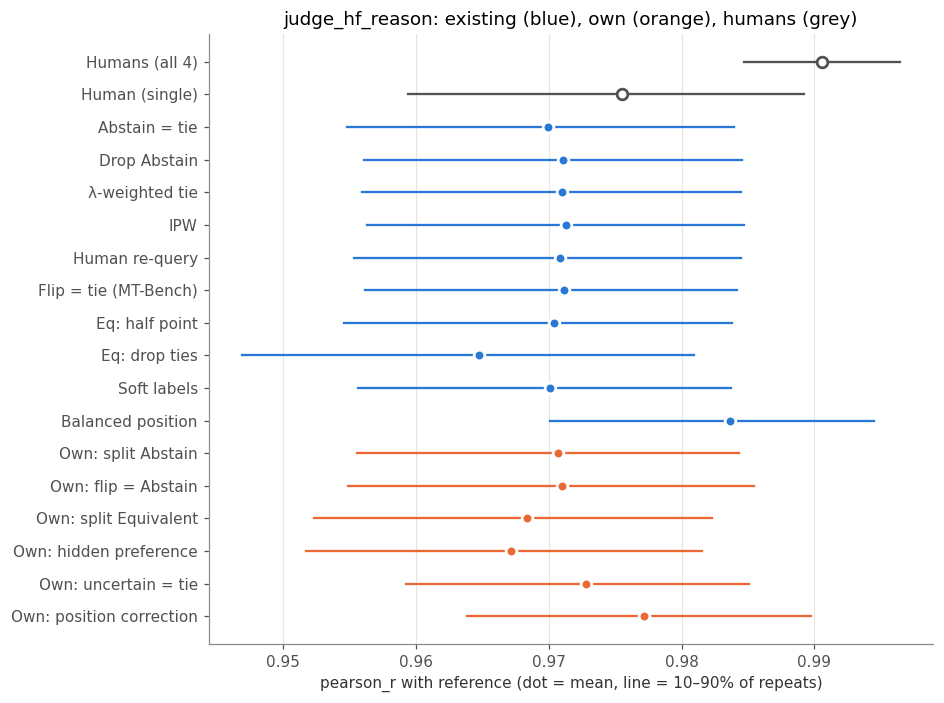

In [ ]:
COLORS = {**{p: "#52514e" for p in HUMANS}, **{p: "#2a78d6" for p in EXISTING}, **{p: "#eb6834" for p in OWN}}
fig, ax = plt.subplots(figsize=(8.5, 7.2))
pols = ORDER[::-1]
m = res.groupby("policy").pearson_r.agg(["mean", lambda s: s.quantile(0.1), lambda s: s.quantile(0.9)]).reindex(pols)
m.columns = ["mean", "lo", "hi"]
for i, pol in enumerate(pols):
    ax.plot([m.lo[pol], m.hi[pol]], [i, i], color=COLORS[pol], lw=1.5)
    ref_line = pol in HUMANS
    ax.plot(m["mean"][pol], i, "o", ms=7, markeredgewidth=1.8,
            markerfacecolor="white" if ref_line else COLORS[pol],
            markeredgecolor=COLORS[pol] if ref_line else "white")
ax.set_yticks(range(len(pols)), pols)
ax.set_xlabel("pearson_r with reference (dot = mean, line = 10–90% of repeats)")
ax.set_title(f"{RUN_NAME}: existing (blue), own (orange), humans (grey)")
ax.grid(axis="y", visible=False)
plt.show()

# Stability vs Drop Abstain

In [ ]:
base = res[res.policy == "Drop Abstain"].set_index("repeat").pearson_r
win = {}
for pol in ORDER:
    if pol == "Drop Abstain":
        continue
    diff = res[res.policy == pol].set_index("repeat").pearson_r - base
    win[pol] = {"better_than_drop_abstain": (diff > 0).mean(), "mean_diff_r": diff.mean()}
pd.DataFrame(win).T.reindex([p for p in ORDER if p != "Drop Abstain"]).round(3)

,better_than_drop_abstain,mean_diff_r
Humans (all 4),0.950,0.019
Human (single),0.640,0.004
Abstain = tie,0.095,-0.001
λ-weighted tie,0.110,-0.000
IPW,0.870,0.000
Human re-query,0.510,-0.000
Flip = tie (MT-Bench),0.500,0.000
Eq: half point,0.340,-0.001
Eq: drop ties,0.200,-0.006
Soft labels,0.330,-0.001


# Diagnostics

In [ ]:
def human_majority(c):
    counts = np.bincount(WIDE.loc[c].dropna().astype(int), minlength=3)
    top = np.flatnonzero(counts == counts.max())
    return ["A", "B", "Tie"][top[0]] if len(top) == 1 else "no majority"

recs["human_majority"] = recs.comparison_id.map({c: human_majority(c) for c in recs.comparison_id.unique()})
display(pd.crosstab(recs.label, recs.human_majority, normalize="index").round(3))

human_majority,A,B,Tie,no majority
label,,,,
A,0.338,0.356,0.096,0.210
Abstain,0.073,0.537,0.195,0.195
B,0.111,0.669,0.054,0.166
Equivalent,0.188,0.440,0.167,0.205


In [ ]:
recs["h_tie"] = recs.comparison_id.map(HUMAN_TIE)
display(recs.groupby("label").h_tie.mean().round(3))

,h_tie
label,
A,0.187
Abstain,0.250
B,0.141
Equivalent,0.258


In [ ]:
display(recs.groupby("category").abstain.agg(["mean", "size"]).sort_values("mean", ascending=False).round(3))

,mean,size
category,,
Closed QA,0.104,48
Extract,0.058,52
Rewrite,0.022,46
Generation,0.016,434
Open QA,0.012,1786
Summarize,0.012,84
Coding,0.008,244
Brainstorm,0.000,150
Chat,0.000,138


In [ ]:
recs["lo"], recs["hi"] = np.minimum(recs.a, recs.b), np.maximum(recs.a, recs.b)
pp = recs.groupby(["lo", "hi"]).agg(abst=("abstain", "mean"), equiv=("label", lambda s: (s == "Equivalent").mean()))
pp

abst  equiv
lo hi              
0  1   0.037  0.468
   2   0.016  0.690
   3   0.021  0.421
   4   0.009  0.472
   5   0.014  0.384
1  2   0.014  0.545
   3   0.016  0.374
   4   0.032  0.375
   5   0.000  0.338
2  3   0.016  0.348
   4   0.011  0.435
   5   0.000  0.388
3  4   0.000  0.568
   5   0.000  0.403
4  5   0.014  0.477

In [ ]:
gaps = np.abs(ref_all_R[pp.index.get_level_values(0)] - ref_all_R[pp.index.get_level_values(1)])
print(f"Correlation with model strength gap over {len(pp)} model pairs: "
      f"Abstain r = {pearsonr(gaps, pp['abst'])[0]:+.2f}, Equivalent r = {pearsonr(gaps, pp['equiv'])[0]:+.2f}")

Correlation with model strength gap over 15 model pairs: Abstain r = -0.01, Equivalent r = -0.76


# Comparison Across Runs

In [ ]:
RUNS = {}
for f in sorted(glob.glob(os.path.join(NOTEBOOK_DIR, "judge_*.jsonl"))):
    name = os.path.basename(f)[:-6]
    if name == "judge_cache_qwen2.5-7b":
        name = "judge_ollama_reason (laptop, CPU)"
    c_ = read_cache(f)
    if c_:
        RUNS[name] = c_
coll_dir = os.path.join(NOTEBOOK_DIR, "collect_qwen2.5-7b-instruct", "chunks")
if os.path.isdir(coll_dir):
    c_ = {}
    for jl in sorted(glob.glob(os.path.join(coll_dir, "chunk_*.jsonl"))):
        if ".tmp" in os.path.basename(jl):
            continue
        for line in open(jl, encoding="utf-8"):
            r = json.loads(line)
            if r.get("phase") == "main" and not r.get("error"):
                c_[(str(r["comparison_id"]), r["variant"])] = {"comparison_id": str(r["comparison_id"]), "order": r["variant"],
                                                               "verdict": r["verdict_shown"], "p": r.get("p_full")}
    if c_:
        RUNS["judge_hf_verdict (collection notebook)"] = c_
print("Runs found:", {k: len(v) for k, v in RUNS.items()})

Runs found: {'judge_hf_reason': 3002, 'judge_hf_verdict (collection notebook)': 3002}


In [ ]:
RECS = {k: make_recs(v) for k, v in RUNS.items()}
common = set(J_rank_ids)
for k, (r_, _, _) in RECS.items():
    full = r_.groupby("comparison_id").order.nunique()
    common &= set(full[full == 2].index)
common = sorted(common)
print(f"Common J_rank pairs with both orders in all runs: {len(common)}")

Common J_rank pairs with both orders in all runs: 1121


In [ ]:
rows = []
for k, (r_, fl, bo) in RECS.items():
    r_ = r_.copy()
    r_["human_majority"] = r_.comparison_id.map({c: human_majority(c) for c in r_.comparison_id.unique()})
    hm = r_.human_majority.map({"A": "A", "B": "B", "Tie": "Equivalent"})
    dec = r_.verdict.isin(["A", "B"])
    r_["lo"], r_["hi"] = np.minimum(r_.a, r_.b), np.maximum(r_.a, r_.b)
    pp = r_.groupby(["lo", "hi"]).agg(abst=("abstain", "mean"), equiv=("label", lambda s_: (s_ == "Equivalent").mean()))
    gg = np.abs(ref_all_R[pp.index.get_level_values(0)] - ref_all_R[pp.index.get_level_values(1)])
    rows.append({"run": k, "n_verdicts": len(r_), "A": (r_.label == "A").mean(), "B": (r_.label == "B").mean(),
                 "Equivalent": (r_.label == "Equivalent").mean(), "Abstain": r_.abstain.mean(),
                 "first_shown_rate": (r_[dec].verdict == "A").mean(),
                 "flip_rate": len(fl) / max(bo.shape[0], 1),
                 "agree_with_majority": (r_.label[hm.notna()] == hm[hm.notna()]).mean(),
                 "eq_vs_gap_r": pearsonr(gg, pp.equiv)[0] if pp.equiv.std() > 0 else np.nan,
                 "abstain_vs_gap_r": pearsonr(gg, pp.abst)[0] if pp.abst.std() > 0 else np.nan})
CMP = pd.DataFrame(rows).set_index("run")
display(CMP.round(3))

,n_verdicts,A,B,Equivalent,Abstain,first_shown_rate,flip_rate,agree_with_majority,eq_vs_gap_r,abstain_vs_gap_r
run,,,,,,,,,,
judge_hf_reason,3002,0.128,0.414,0.444,0.014,0.630,0.115,0.486,-0.757,-0.010
judge_hf_verdict (collection notebook),3002,0.100,0.242,0.613,0.045,0.807,0.104,0.356,-0.815,-0.201


In [ ]:
names = list(RUNS)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for x in names:
    for y_ in names:
        keys = set(RUNS[x]) & set(RUNS[y_])
        agree.loc[x, y_] = np.mean([RUNS[x][k_]["verdict"] == RUNS[y_][k_]["verdict"] for k_ in keys]) if keys else np.nan
display(agree.round(3))

,judge_hf_reason,judge_hf_verdict (collection notebook)
judge_hf_reason,1.000,0.587
judge_hf_verdict (collection notebook),0.587,1.000


In [ ]:
POLS_CMP = ["Drop Abstain", "Abstain = tie", "Flip = tie (MT-Bench)", "Own: flip = Abstain"]
def few_policies(d):
    a, b, y, w = d.a.to_numpy(), d.b.to_numpy(), d.y.to_numpy(), d.w.to_numpy()
    abst, flip = d.abstain.to_numpy(), d.flip.to_numpy()
    obs = ~abst
    keep = obs & ~flip
    return {"Drop Abstain": fit_rk(a[obs], b[obs], y[obs], w[obs]),
            "Abstain = tie": fit_rk(a, b, np.where(abst, E, y), w),
            "Flip = tie (MT-Bench)": fit_rk(a[obs], b[obs], np.where(flip, E, y)[obs], w[obs]),
            "Own: flip = Abstain": fit_rk(a[keep], b[keep], y[keep], w[keep])}

sub = {k: r_[r_.comparison_id.isin(set(common))].reset_index(drop=True) for k, (r_, _, _) in RECS.items()}
idx_by = {k: v.groupby("comparison_id").indices for k, v in sub.items()}
hum_c = ann_cross[ann_cross.comparison_id.isin(set(common))].reset_index(drop=True)
hum_c

,comparison_id,prompt_id,category,model_a,model_b,slot,y,a,b,self_pair
0,ea9fe3ea6ad14272a5dee6d86bb3aee2,03300eaf7132417aa7bdb9d2a126d75d,Open QA,allenai/tulu-2-70b,gpt-3.5-turbo-0125,normal_0,0,0,2,False
1,ea9fe3ea6ad14272a5dee6d86bb3aee2,03300eaf7132417aa7bdb9d2a126d75d,Open QA,allenai/tulu-2-70b,gpt-3.5-turbo-0125,normal_1,2,0,2,False
2,ea9fe3ea6ad14272a5dee6d86bb3aee2,03300eaf7132417aa7bdb9d2a126d75d,Open QA,allenai/tulu-2-70b,gpt-3.5-turbo-0125,expert_0,0,0,2,False
3,ea9fe3ea6ad14272a5dee6d86bb3aee2,03300eaf7132417aa7bdb9d2a126d75d,Open QA,allenai/tulu-2-70b,gpt-3.5-turbo-0125,expert_1,0,0,2,False
4,80b05c772384407d92c705aaf09efc76,059d42e6b34840fe947ebb90c79e46ae,Open QA,allenai/tulu-2-7b,gpt-4-turbo-2024-04-09,normal_0,2,1,3,False
...,...,...,...,...,...,...,...,...,...,...
4479,7c18b1b0eccd438bb83ab70ddf129694,f3511ee58a5f450ebc928d6051edb0fa,Coding,allenai/tulu-2-7b,meta-llama/Llama-2-70b-chat-hf,expert_1,2,1,4,False
4480,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,normal_0,1,2,5,False
4481,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,normal_1,1,2,5,False
4482,78f3fbf0e8454c1786bc3435fd043f6e,ff0638b23a2b4540b9e02fb5a7b16a59,Coding,gpt-3.5-turbo-0125,meta-llama/Meta-Llama-3-70B-Instruct,expert_0,0,2,5,False


In [ ]:
hum_c_by = hum_c.groupby("comparison_id").indices
common_arr = np.array(common)
recs_cmp = []
for rep in range(N_REPS):
    rng = np.random.default_rng(10_000 + rep)
    perm = rng.permutation(R_prompts)
    ref_test = human_rating(ann_cross.prompt_id.isin(set(perm[: int(TEST_SHARE_OF_R * len(perm))])))
    boot = rng.choice(common_arr, size=len(common_arr), replace=True)
    for k, v in sub.items():
        d = v.iloc[np.concatenate([idx_by[k][c] for c in boot])].reset_index(drop=True)
        for pol, s_hat in few_policies(d).items():
            recs_cmp.append({"run": k, "policy": pol, "repeat": rep, **compare(s_hat, ref_test)})
    h = hum_c.iloc[np.concatenate([hum_c_by[c] for c in boot if c in hum_c_by])]
    recs_cmp.append({"run": "humans", "policy": "Humans (all 4)", "repeat": rep, **compare(fit_rk(h.a, h.b, h.y), ref_test)})
    h1 = h[h.slot == "normal_0"]
    recs_cmp.append({"run": "humans", "policy": "Human (single)", "repeat": rep, **compare(fit_rk(h1.a, h1.b, h1.y), ref_test)})
RC = pd.DataFrame(recs_cmp)
RC

,run,policy,repeat,kendall_tau,inverted_pairs,pearson_r
0,judge_hf_reason,Drop Abstain,0,0.600,3,0.942
1,judge_hf_reason,Abstain = tie,0,0.600,3,0.941
2,judge_hf_reason,Flip = tie (MT-Bench),0,0.600,3,0.943
3,judge_hf_reason,Own: flip = Abstain,0,0.600,3,0.943
4,judge_hf_verdict (collection notebook),Drop Abstain,0,1.000,0,0.966
...,...,...,...,...,...,...
1995,judge_hf_verdict (collection notebook),Abstain = tie,199,0.733,2,0.949
1996,judge_hf_verdict (collection notebook),Flip = tie (MT-Bench),199,0.733,2,0.946
1997,judge_hf_verdict (collection notebook),Own: flip = Abstain,199,0.733,2,0.950
1998,humans,Humans (all 4),199,1.000,0,0.996


In [ ]:
tab = RC.groupby(["run", "policy"])[["kendall_tau", "inverted_pairs", "pearson_r"]].mean().unstack("policy")
tab

kendall_tau                                                                                      inverted_pairs               \
policy                                 Abstain = tie Drop Abstain Flip = tie (MT-Bench) Human (single) Humans (all 4) Own: flip = Abstain  Abstain = tie Drop Abstain   
run                                                                                                                                                                     
humans                                           NaN          NaN                   NaN          0.891          0.871                 NaN            NaN          NaN   
judge_hf_reason                                0.743        0.745                 0.743            NaN            NaN               0.747          1.930        1.915   
judge_hf_verdict (collection notebook)         0.811        0.813                 0.820            NaN            NaN               0.821          1.415        1.400   

                                                                                                                   pearson_r                                     \
policy                                 Flip = tie (MT-Bench) Human (single) Humans (all 4) Own: flip = Abstain Abstain = tie Drop Abstain Flip = tie (MT-Bench)   
run                                                                                                                                                               
humans                                                   NaN           0.82          0.965                 NaN           NaN          NaN                   NaN   
judge_hf_reason                                        1.925            NaN            NaN               1.900         0.969        0.970                 0.970   
judge_hf_verdict (collection notebook)                 1.350            NaN            NaN               1.345         0.965        0.962                 0.964   

                                                                                          
policy                                 Human (single) Humans (all 4) Own: flip = Abstain  
run                                                                                       
humans                                          0.976          0.991                 NaN  
judge_hf_reason                                   NaN            NaN               0.970  
judge_hf_verdict (collection notebook)            NaN            NaN               0.965

In [ ]:
display(tab["pearson_r"].round(3))

policy,Abstain = tie,Drop Abstain,Flip = tie (MT-Bench),Human (single),Humans (all 4),Own: flip = Abstain
run,,,,,,
humans,NaN,NaN,NaN,0.976,0.991,NaN
judge_hf_reason,0.969,0.970,0.970,NaN,NaN,0.970
judge_hf_verdict (collection notebook),0.965,0.962,0.964,NaN,NaN,0.965


In [ ]:
display(tab["kendall_tau"].round(3))

policy,Abstain = tie,Drop Abstain,Flip = tie (MT-Bench),Human (single),Humans (all 4),Own: flip = Abstain
run,,,,,,
humans,NaN,NaN,NaN,0.891,0.871,NaN
judge_hf_reason,0.743,0.745,0.743,NaN,NaN,0.747
judge_hf_verdict (collection notebook),0.811,0.813,0.820,NaN,NaN,0.821


In [ ]:
CMP.to_csv(os.path.join(NOTEBOOK_DIR, "judge_compare_behaviour.csv"))
RC.to_csv(os.path.join(NOTEBOOK_DIR, "judge_compare_ranking_reps.csv"), index=False)